# Episode playback & analysis

Loads a run recorded with `arena-launch.sh --record` (see `docs/12-recording-and-playback.md`), prints the
per-episode metrics, and replays an episode. Start Jupyter from the repo with `uv run jupyter lab`.

By default this picks the **newest** run in `~/arena_runs`; set `RUN` to a path to look at a specific one.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from arena_analysis import load_run

RUN = None   # e.g. "~/arena_runs/20261011-021540_dsrnn_hallway_tame"
if RUN is None:
    RUN = sorted(Path("~/arena_runs").expanduser().glob("*_*"))[-1]
run = load_run(RUN)
run, run.episodes

(<Run 20261011-021540_dsrnn_hallway_tame: 3 episode(s)>,
 [<Episode 0 dsrnn hallway_tame.json outcome=success duration=65.6s>,
  <Episode 1 dsrnn hallway_tame.json outcome=success duration=84.8s>,
  <Episode 2 dsrnn hallway_tame.json outcome=incomplete duration=16.9s>])

## Metrics for every episode
One row per episode. Every key is explained in `arena_analysis.metrics.summarize` and docs/12.

In [2]:
run.summary().round(2)

,episode,planner,scenario,outcome,success,duration,path_length,final_goal_dist,reached_goal,path_efficiency,...,max_speed,n_humans,min_clearance,min_center_dist,collisions,collision_time,intrusion_time,min_wall_clearance,wall_collision,cmd_tracking_err
0,0,dsrnn,hallway_tame.json,success,True,65.60,62.52,0.16,True,0.93,...,1.01,20,0.13,0.80,0,0.0,4.00,0.83,False,0.00
1,1,dsrnn,hallway_tame.json,success,True,84.85,69.33,0.11,True,0.84,...,1.01,20,-0.06,0.61,2,0.9,13.19,0.83,False,0.01
2,2,dsrnn,hallway_tame.json,incomplete,False,16.95,16.93,41.29,False,NaN,...,1.01,20,1.90,2.57,0,0.0,0.00,0.83,False,0.00


## The raw tables
`ep.robot` has one row per 10 Hz sample, `ep.humans` one row per sample and pedestrian.

In [3]:
ep = run.episodes[0]
ep.robot.head()

,t,x,y,yaw,odom_vx,odom_vy,odom_wz,cmd_nav_vx,cmd_nav_wz,cmd_vx,cmd_wz,t_rel,vx,vy,speed,goal_dist
0,24.4422,1.0000,6.0000,-0.0000,0.0000,0.0000,0.0000,0.1,-1.0,0.1,-1.0,0.0332,0.027027,0.034535,0.043853,58.000000
1,24.5088,1.0018,6.0023,-0.0369,0.0053,0.0071,-0.1108,0.1,-1.0,0.1,-1.0,0.0998,0.122523,0.039640,0.128775,57.998200
2,24.6087,1.0204,6.0066,-0.0977,0.0598,0.0252,-0.2933,0.9,1.0,0.9,1.0,0.1997,0.471972,-0.019520,0.472375,57.979600
3,24.7086,1.0961,5.9984,-0.0912,0.2884,0.0223,-0.2740,1.0,1.0,1.0,1.0,0.2996,0.842843,-0.115115,0.850668,57.903900
4,24.8085,1.1888,5.9836,-0.0316,0.5681,-0.0091,-0.0495,1.0,1.0,1.0,1.0,0.3995,0.963463,-0.134134,0.972756,57.811202


In [4]:
ep.humans.head()

,t,t_msg,id,name,group_id,x,y,yaw,vx,vy,radius,t_rel,vx_fd,vy_fd
0,24.4422,24.4422,20,from_corridor_2,-1,15.00,14.00,0.0,0.6137,0.5728,0.35,0.0332,-3.010210,-15.342342
1,24.4422,24.4422,19,from_corridor_1,-1,45.00,-2.00,0.0,0.0000,-0.0000,0.35,0.0332,-0.078078,13.340541
2,24.4422,24.4422,18,from_corridor_0,-1,30.00,-2.00,0.0,0.0000,-0.0000,0.35,0.0332,1.114114,14.933934
3,24.4422,24.4422,17,friend_group_4,2,47.61,6.52,0.0,0.0000,0.0000,0.35,0.0332,-11.829429,-0.027027
4,24.4422,24.4422,16,friend_group_3,2,47.61,7.32,0.0,0.0000,0.0000,0.35,0.0332,-11.829429,0.022222


## One frame
`t` is absolute sim time, like the `t` column (`ep.meta['t_start']` is the episode start).

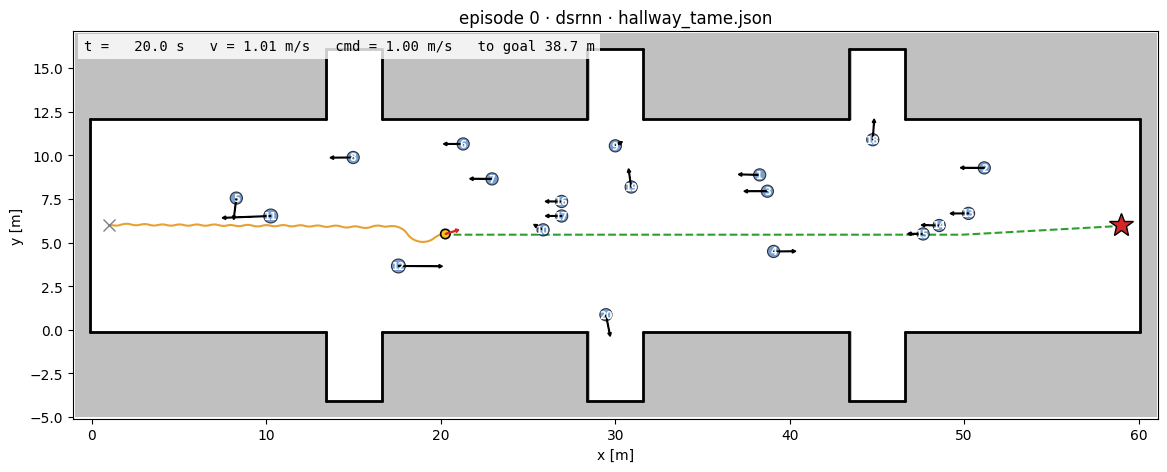

In [5]:
ep.plot(t=ep.meta["t_start"] + 20);

## Speed and distance to the nearest pedestrian over time

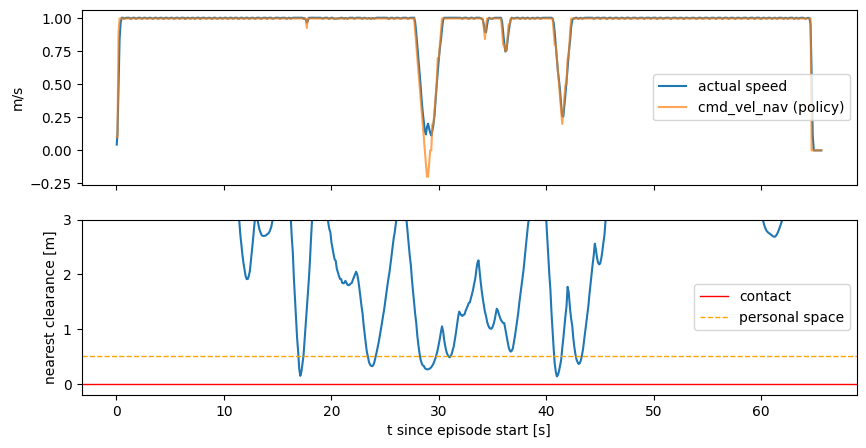

In [6]:
d = ep.distances()                                   # one row per (sample, pedestrian)
nearest = d.groupby("t")["clearance"].min()
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
t0 = ep.meta["t_start"]
a1.plot(ep.robot["t"] - t0, ep.robot["speed"], label="actual speed")
a1.plot(ep.robot["t"] - t0, ep.robot["cmd_nav_vx"], label="cmd_vel_nav (policy)", alpha=0.7)
a1.set_ylabel("m/s"); a1.legend()
a2.plot(nearest.index - t0, nearest.values)
a2.axhline(0, color="red", lw=1, label="contact"); a2.axhline(0.5, color="orange", lw=1, ls="--", label="personal space")
a2.set_ylabel("nearest clearance [m]"); a2.set_xlabel("t since episode start [s]"); a2.legend()
a2.set_ylim(-0.2, 3);

## Contacts (collisions)
Runs of consecutive samples where the robot disc overlaps a pedestrian disc.

In [7]:
pd.concat({e.index: e.collisions() for e in run.episodes}, names=["episode"])

/tmp/ipykernel_67054/3713020282.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat({e.index: e.collisions() for e in run.episodes}, names=["episode"])


id      name   t_start     t_end  duration  min_clearance
episode                                                             
1       0  11  runner_0  139.3272  139.6269    0.2997      -0.059585
        1  12  runner_1  135.3312  135.7308    0.3996      -0.052575

## Replay
`ep.play()` embeds a video (needs ffmpeg; the uv env bundles one via `imageio-ffmpeg`). It's a few MB, so its
output is cleared in the committed notebook. `view="follow"` zooms in on the robot.
`ep.save_video("ep0.mp4")` writes a file instead.

In [ ]:
ep.play(speed=8, fps=10)